# Start Trek — DQN

Agent DQN entraîné à poser le module de `LunarLander-v3`.

Objectif : score moyen ≥ 200 sur 100 épisodes consécutifs, sans exploration.

## Sommaire

1. Imports et configuration
2. Environnement
3. Raison de fin d'épisode
4. Boucle d'épisode et logs
5. Baseline : agent random
6. Hyperparamètres
7. Réseau Q et loss
8. Replay buffer
9. Epsilon-greedy
10. Target network et update
11. Évaluation sans exploration
12. Boucle d'entraînement
13. Courbes d'entraînement
14. Sauvegarde du modèle
15. Tuning des hyperparamètres
16. Évaluation sur 100 épisodes consécutifs
17. Raisons de fin pendant l'entraînement
18. Résultats sur 3 seeds
19. Expérience comparative : hard vs soft update

## 1. Imports et configuration

Toutes les seeds sont regroupées ici pour que les résultats soient reproductibles.

`TRAIN` : à `True`, le notebook entraîne l'agent. À `False`, il recharge le modèle et l'historique depuis `models/` et `results/dqn/` au lieu de réentraîner, ce qui permet de refaire tous les plots en quelques secondes.

`TUNE` : même principe pour le tuning de la section 15, qui enchaîne une vingtaine d'entraînements. À `False`, on recharge `results/dqn/tuning.json`.

`EXPERIMENTS` : pareil pour les sections 18 et 19 (3 seeds et hard vs soft update, 5 entraînements). À `False`, on recharge `results/dqn/seeds.json` et `results/dqn/hard_vs_soft.json`.

In [ ]:
import json
import random
import time
from collections import Counter
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

In [ ]:
TRAIN = False
TUNE = False
EXPERIMENTS = False

ENV_ID = "LunarLander-v3"
SEED = 0
SEEDS = [0, 1, 2]

RESULTS_DIR = Path("results/dqn")
MODELS_DIR = Path("models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed, env=None):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if env is not None:
        env.reset(seed=seed)
        env.action_space.seed(seed)


set_seed(SEED)

## 2. Environnement

Deux façons de créer l'environnement :

- **entraînement / évaluation** : `render_mode=None`, aucun rendu, c'est beaucoup plus rapide ;
- **visualisation** : `render_mode="human"`, uniquement pour regarder l'agent jouer.

La taille de l'état et le nombre d'actions sont lus depuis l'environnement, pas écrits en dur.

In [ ]:
def make_env(render_mode=None):
    return gym.make(ENV_ID, render_mode=render_mode)


env = make_env()
OBS_DIM = int(env.observation_space.shape[0])
N_ACTIONS = int(env.action_space.n)
MAX_STEPS = env.spec.max_episode_steps

print(f"Taille de l'état : {OBS_DIM}")
print(f"Nombre d'actions : {N_ACTIONS}")
print(f"Steps max par épisode : {MAX_STEPS}")

Taille de l'état : 8
Nombre d'actions : 4
Steps max par épisode : 1000


## 3. Raison de fin d'épisode

Gymnasium renvoie seulement `terminated` et `truncated`, pas la raison exacte. On la déduit de la dernière transition `(state, reward, terminated, truncated)` :

| Label | Condition |
| --- | --- |
| `truncated` | `truncated` (limite de steps atteinte) |
| `out_of_viewport` | `abs(x) >= 1` |
| `at_rest` | reward du dernier step > 0 (l'atterrissage donne +100) |
| `crash` | sinon (le crash donne -100) |

On n'utilise pas l'état interne de l'environnement (`env.unwrapped`) : la même fonction marche aussi avec des environnements vectorisés. C'est la même fonction dans `ppo.ipynb`, pour que les stats de fin des deux agents soient comparables.

In [ ]:
END_REASONS = ["crash", "out_of_viewport", "at_rest", "truncated"]


def get_end_reason(state, reward, terminated, truncated):
    if truncated and not terminated:
        return "truncated"
    if abs(state[0]) >= 1.0:
        return "out_of_viewport"
    if reward > 0:
        return "at_rest"
    return "crash"

## 4. Boucle d'épisode et logs

`run_episode` joue un épisode complet avec une politique donnée (une fonction `state -> action`) et renvoie un log :

| Champ | Contenu |
| --- | --- |
| `episode` | numéro de l'épisode |
| `reward` | reward totale |
| `length` | nombre de steps |
| `end_reason` | raison de fin (section 3) |
| `global_step` | nombre total de steps joués depuis le début |
| `wall_time` | temps écoulé depuis le début (secondes) |

Ce format est le même dans `ppo.ipynb`, pour pouvoir comparer les deux agents.

In [ ]:
def run_episode(env, policy, seed=None, episode=0, global_step=0, start_time=None):
    if start_time is None:
        start_time = time.time()
    state, _ = env.reset(seed=seed)
    total_reward = 0.0
    length = 0
    done = False

    while not done:
        action = policy(state)
        state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        length += 1
        done = terminated or truncated

    return {
        "episode": episode,
        "reward": float(total_reward),
        "length": length,
        "end_reason": get_end_reason(state, reward, terminated, truncated),
        "global_step": global_step + length,
        "wall_time": time.time() - start_time,
    }


def summarize(logs):
    rewards = np.array([log["reward"] for log in logs])
    reasons = Counter(log["end_reason"] for log in logs)
    return {
        "n_episodes": len(logs),
        "mean": float(rewards.mean()),
        "std": float(rewards.std()),
        "min": float(rewards.min()),
        "max": float(rewards.max()),
        "end_reasons": {reason: reasons.get(reason, 0) for reason in END_REASONS},
    }

## 5. Baseline : agent random

Avant d'entraîner quoi que ce soit, on joue 100 épisodes en choisissant les actions au hasard. Ça donne un score de référence et ça vérifie que les logs marchent.

Chaque épisode `i` utilise la seed `SEED + i` : la baseline est identique à chaque exécution.

In [ ]:
N_BASELINE_EPISODES = 100

set_seed(SEED, env)
random_policy = lambda state: env.action_space.sample()

baseline_logs = []
global_step = 0
start_time = time.time()
for i in range(N_BASELINE_EPISODES):
    log = run_episode(env, random_policy, seed=SEED + i, episode=i,
                      global_step=global_step, start_time=start_time)
    global_step = log["global_step"]
    baseline_logs.append(log)

baseline = summarize(baseline_logs)
print(f"Score moyen : {baseline['mean']:.1f} ± {baseline['std']:.1f}")
print(f"Min / max   : {baseline['min']:.1f} / {baseline['max']:.1f}")
print(f"Raisons de fin : {baseline['end_reasons']}")

Score moyen : -192.1 ± 114.4
Min / max   : -462.5 / 8.3
Raisons de fin : {'crash': 92, 'out_of_viewport': 8, 'at_rest': 0, 'truncated': 0}


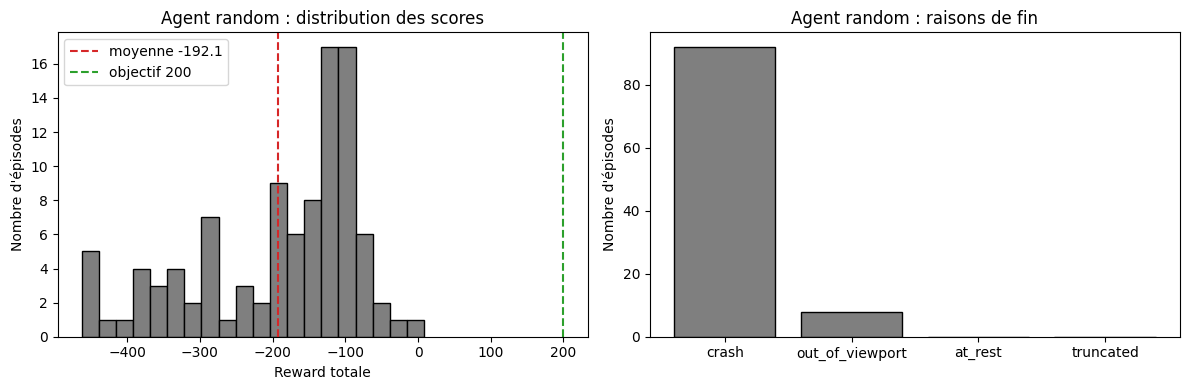

In [ ]:
rewards = [log["reward"] for log in baseline_logs]
reasons = baseline["end_reasons"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(rewards, bins=20, color="tab:gray", edgecolor="black")
axes[0].axvline(baseline["mean"], color="tab:red", linestyle="--", label=f"moyenne {baseline['mean']:.1f}")
axes[0].axvline(200, color="tab:green", linestyle="--", label="objectif 200")
axes[0].set_title("Agent random : distribution des scores")
axes[0].set_xlabel("Reward totale")
axes[0].set_ylabel("Nombre d'épisodes")
axes[0].legend()

axes[1].bar(reasons.keys(), reasons.values(), color="tab:gray", edgecolor="black")
axes[1].set_title("Agent random : raisons de fin")
axes[1].set_ylabel("Nombre d'épisodes")

plt.tight_layout()
plt.show()

In [ ]:
with open(RESULTS_DIR / "baseline_random.json", "w") as f:
    json.dump({"summary": baseline, "episodes": baseline_logs}, f, indent=2)

**Analyse :** l'agent random fait **-192 ± 115** en moyenne, avec un meilleur épisode à 8 seulement. Il se crashe dans 92 épisodes sur 100 et sort de l'écran dans les 8 autres, en 90 steps en moyenne. Il ne se pose jamais et n'arrive jamais à la limite de temps.

Il faut donc gagner environ 400 points pour atteindre 200. Le premier problème à résoudre est de ne pas tomber : le moteur principal est indispensable pour freiner, et le hasard ne l'utilise pas assez longtemps.

## 6. Hyperparamètres

Tous les hyperparamètres du DQN sont regroupés ici. C'est la **config finale**, retenue après le tuning de la section 15. Les deux valeurs modifiées par rapport à la config de départ sont en gras ; la config de départ complète est gardée dans `BASE_CONFIG` (section 15).

| Paramètre | Valeur | Raison |
| --- | --- | --- |
| `gamma` | 0.99 | un atterrissage prend plusieurs centaines de steps, le +100 final doit remonter jusqu'aux premières actions |
| `lr` | 5e-4 | valeur classique avec Adam sur un petit MLP |
| **`batch_size`** | **128** (départ : 64) | tuning : éval 238 contre 208 pour la référence, et un apprentissage plus stable (100 derniers épisodes à 236 contre 175) |
| `buffer_capacity` | 100 000 | une centaine d'épisodes : assez de diversité sans garder des expériences trop vieilles |
| `learning_starts` | 1 000 | on ne s'entraîne pas sur un buffer presque vide |
| **`hidden_sizes`** | **(256, 256)** (départ : (128, 128)) | tuning : avec batch 128, meilleure config testée (éval 268 sur les 2 seeds). 64x64 est trop petit (éval 51) |
| `eps_start` / `eps_end` | 1.0 / 0.01 | 100 % d'exploration au début, presque plus à la fin |
| `eps_decay_steps` | 100 000 | voir section 9 |
| `tau` | 0.005 | voir section 10 |
| `total_steps` | 300 000 | voir section 12 |
| `train_freq` | 4 | voir section 12 |
| `eval_every` / `eval_episodes` | 10 000 / 10 | voir section 12 |

In [ ]:
CONFIG = {
    "gamma": 0.99,
    "lr": 5e-4,
    "batch_size": 128,
    "buffer_capacity": 100_000,
    "learning_starts": 1_000,
    "hidden_sizes": (256, 256),
    "eps_start": 1.0,
    "eps_end": 0.01,
    "eps_decay_steps": 100_000,
    "tau": 0.005,
    "total_steps": 300_000,
    "train_freq": 4,
    "eval_every": 10_000,
    "eval_episodes": 10,
}

## 7. Réseau Q et loss

L'état est continu : impossible de stocker une Q-table. On utilise un **MLP** qui prend l'état en entrée et sort **une Q-value par action** :

`état (8) → Linear → ReLU → Linear → ReLU → Linear → Q-values (4)`

Avec une sortie par action, un seul passage dans le réseau donne les 4 Q-values d'un état. Choisir la meilleure action, c'est juste un `argmax`.

**Loss : MSE.** Pour une expérience `(s, a, r, s', done)` on construit une cible avec l'équation de Bellman :

- `target = r` si l'épisode est vraiment fini (`done`) ;
- `target = r + γ · max_a' Q_target(s', a')` sinon.

La loss est l'erreur quadratique moyenne entre la Q-value prédite pour l'action jouée, `Q(s, a)`, et cette cible. Seule la Q-value de l'action jouée est corrigée : on ne sait rien des 3 autres.

In [ ]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden_sizes=(128, 128)):
        super().__init__()
        layers = []
        in_size = obs_dim
        for size in hidden_sizes:
            layers += [nn.Linear(in_size, size), nn.ReLU()]
            in_size = size
        layers.append(nn.Linear(in_size, n_actions))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


q_net = QNetwork(OBS_DIM, N_ACTIONS, CONFIG["hidden_sizes"]).to(DEVICE)
print(q_net)
print(f"Paramètres : {sum(p.numel() for p in q_net.parameters())}")

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=4, bias=True)
  )
)
Paramètres : 69124


## 8. Replay buffer

Deux steps qui se suivent sont presque identiques. Apprendre dessus dans l'ordre rend l'entraînement instable. Le replay buffer stocke les expériences et on apprend sur des **batches tirés au hasard**.

- **capacité fixe** : tableaux numpy pré-alloués, utilisés en cercle. Une fois plein, la nouvelle expérience écrase la plus vieille.
- **`sample`** renvoie des tenseurs groupés par élément (`states`, `actions`, ...), prêts pour le réseau.
- **`len`** donne le nombre d'expériences stockées, pour savoir quand commencer à apprendre.

**Ce qu'on stocke dans `done` : `terminated` uniquement.** Quand l'épisode est `truncated`, le module aurait pu continuer : la cible doit garder `γ · max Q(s')`. Si on mettait `done = True`, on apprendrait à l'agent qu'il n'y a plus rien à gagner après la limite de temps, ce qui est faux.

In [ ]:
class ReplayBuffer:
    def __init__(self, capacity, obs_dim):
        self.capacity = capacity
        self.states = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.next_states = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.dones = np.zeros(capacity, dtype=np.float32)
        self.pos = 0
        self.size = 0

    def push(self, state, action, reward, next_state, done):
        self.states[self.pos] = state
        self.actions[self.pos] = action
        self.rewards[self.pos] = reward
        self.next_states[self.pos] = next_state
        self.dones[self.pos] = done
        self.pos = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        idx = np.random.randint(0, self.size, size=batch_size)
        return (
            torch.as_tensor(self.states[idx], device=DEVICE),
            torch.as_tensor(self.actions[idx], device=DEVICE),
            torch.as_tensor(self.rewards[idx], device=DEVICE),
            torch.as_tensor(self.next_states[idx], device=DEVICE),
            torch.as_tensor(self.dones[idx], device=DEVICE),
        )

    def __len__(self):
        return self.size

Vérification : un buffer de capacité 3 qui reçoit 5 expériences ne doit garder que les 3 dernières.

In [ ]:
test_buffer = ReplayBuffer(capacity=3, obs_dim=OBS_DIM)
for i in range(5):
    test_buffer.push(np.full(OBS_DIM, i), i % N_ACTIONS, float(i), np.full(OBS_DIM, i + 1), False)

print(f"Taille : {len(test_buffer)}")
print(f"Rewards stockées : {sorted(test_buffer.rewards.tolist())}")

states, actions, rewards, next_states, dones = test_buffer.sample(4)
print(f"Shapes : {tuple(states.shape)} {tuple(actions.shape)} {tuple(rewards.shape)} {tuple(next_states.shape)} {tuple(dones.shape)}")

Taille : 3
Rewards stockées : [2.0, 3.0, 4.0]
Shapes : (4, 8) (4,) (4,) (4, 8) (4,)


## 9. Epsilon-greedy

- avec une probabilité `ε` : action au hasard (exploration) ;
- sinon : action avec la plus grande Q-value (exploitation).

**Décroissance choisie : linéaire, par step**, de `eps_start` à `eps_end` sur `eps_decay_steps` steps, puis constante.

- **par step plutôt que par épisode** : la longueur des épisodes change énormément (un crash rapide fait ~70 steps, un atterrissage plusieurs centaines). Compter en steps relie l'exploration à la quantité d'expérience réellement vécue.
- **linéaire plutôt qu'exponentielle** : le temps passé à explorer se lit directement dans un seul paramètre. Une exponentielle descend très vite au début, au moment où l'agent ne sait encore rien.

En évaluation, `ε = 0` : l'agent prend toujours la meilleure action.

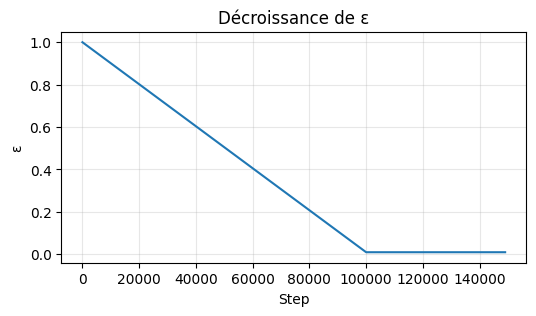

In [ ]:
def get_epsilon(step, eps_start=CONFIG["eps_start"], eps_end=CONFIG["eps_end"],
                decay_steps=CONFIG["eps_decay_steps"]):
    progress = min(step / decay_steps, 1.0)
    return eps_start + progress * (eps_end - eps_start)


def select_action(q_net, state, epsilon):
    if np.random.random() < epsilon:
        return np.random.randint(N_ACTIONS)
    with torch.no_grad():
        state_t = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        return int(q_net(state_t).argmax(dim=1).item())


steps = np.arange(0, 150_000, 1_000)
plt.figure(figsize=(6, 3))
plt.plot(steps, [get_epsilon(s) for s in steps])
plt.title("Décroissance de ε")
plt.xlabel("Step")
plt.ylabel("ε")
plt.grid(alpha=0.3)
plt.show()

## 10. Target network et update

Si la cible est calculée avec le réseau qu'on entraîne, elle bouge à chaque update : on vise une cible qui se déplace et l'entraînement devient instable. Le **target network** est une copie du réseau principal, utilisée seulement pour calculer les cibles, et mise à jour plus lentement.

Deux stratégies possibles :

- **hard update** : on recopie tous les poids tous les N steps. La cible reste fixe pendant N steps, puis change d'un coup.
- **soft update** : à chaque step, `θ_target ← τ · θ + (1 − τ) · θ_target`. La cible suit le réseau principal en douceur.

**Choix : soft update avec `τ = 0.005`.** La cible ne fait jamais de saut brusque, ce qui évite les pics de loss qu'on a juste après une copie en hard update. Avec `τ = 0.005`, le target network « oublie » ses anciens poids sur environ `1/τ = 200` steps, l'équivalent d'un hard update toutes les quelques centaines de steps. La comparaison hard vs soft sera faite dans l'expérience comparative.

In [ ]:
def soft_update(target_net, q_net, tau):
    with torch.no_grad():
        for target_param, param in zip(target_net.parameters(), q_net.parameters()):
            target_param.mul_(1 - tau).add_(tau * param)


def hard_update(target_net, q_net):
    target_net.load_state_dict(q_net.state_dict())


def compute_targets(target_net, rewards, next_states, dones, gamma):
    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1).values
    return rewards + gamma * next_q * (1 - dones)


def dqn_update(q_net, target_net, optimizer, buffer, batch_size, gamma):
    states, actions, rewards, next_states, dones = buffer.sample(batch_size)
    q_values = q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)
    targets = compute_targets(target_net, rewards, next_states, dones, gamma)
    loss = nn.functional.mse_loss(q_values, targets)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()

Vérifications :

1. une expérience terminée (`done = 1`) doit avoir une cible égale à `r` ;
2. un update complet sur un buffer rempli d'expériences random doit renvoyer une loss finie.

In [ ]:
target_net = QNetwork(OBS_DIM, N_ACTIONS, CONFIG["hidden_sizes"]).to(DEVICE)
hard_update(target_net, q_net)

rewards_t = torch.tensor([100.0, 1.0])
next_states_t = torch.zeros((2, OBS_DIM))
dones_t = torch.tensor([1.0, 0.0])
print(f"Cibles : {compute_targets(target_net, rewards_t, next_states_t, dones_t, CONFIG['gamma']).tolist()}")

buffer = ReplayBuffer(CONFIG["buffer_capacity"], OBS_DIM)
state, _ = env.reset(seed=SEED)
for _ in range(CONFIG["learning_starts"]):
    action = env.action_space.sample()
    next_state, reward, terminated, truncated, _ = env.step(action)
    buffer.push(state, action, reward, next_state, terminated)
    state = next_state if not (terminated or truncated) else env.reset()[0]

optimizer = torch.optim.Adam(q_net.parameters(), lr=CONFIG["lr"])
loss = dqn_update(q_net, target_net, optimizer, buffer, CONFIG["batch_size"], CONFIG["gamma"])
soft_update(target_net, q_net, CONFIG["tau"])
print(f"Buffer : {len(buffer)} expériences, loss du premier update : {loss:.3f}")

Cibles : [100.0, 1.0818730592727661]
Buffer : 1000 expériences, loss du premier update : 319.497


## 11. Évaluation sans exploration

Pendant l'évaluation, l'agent ne doit plus explorer : `ε = 0`, il prend toujours l'action avec la plus grande Q-value.

Les épisodes d'évaluation utilisent les seeds `EVAL_SEED_OFFSET + i`, différentes de celles de l'entraînement : on mesure l'agent sur des situations qu'il n'a pas forcément déjà vues.

In [ ]:
EVAL_SEED_OFFSET = 10_000


def evaluate(q_net, n_episodes, seed_offset=EVAL_SEED_OFFSET, render_mode=None):
    eval_env = make_env(render_mode)
    greedy_policy = lambda state: select_action(q_net, state, epsilon=0.0)
    logs = [run_episode(eval_env, greedy_policy, seed=seed_offset + i, episode=i)
            for i in range(n_episodes)]
    eval_env.close()
    return logs

## 12. Boucle d'entraînement

À chaque step : l'agent choisit une action (epsilon-greedy), la joue, stocke l'expérience dans le replay buffer, et apprend si c'est le moment.

**Budget : 300 000 steps.** On compte en steps plutôt qu'en épisodes pour la même raison que pour `ε` : la longueur des épisodes varie énormément. 100 000 steps servent à faire descendre `ε`, il en reste 200 000 où l'agent exploite surtout ce qu'il a appris.

**Fréquence d'apprentissage : un update tous les 4 steps** (`train_freq`), une fois que le buffer contient `learning_starts` expériences. Apprendre à chaque step coûte 4 fois plus de calcul pour un gain faible : deux steps consécutifs ajoutent des expériences presque identiques. Avec un batch de 128 tous les 4 steps, chaque expérience est quand même réutilisée en moyenne 32 fois pendant son passage dans le buffer.

**Évaluation régulière :** tous les `eval_every` steps, on évalue l'agent sur `eval_episodes` épisodes sans exploration. On garde une copie des poids qui ont le meilleur score moyen : c'est cette version qui est sauvegardée, pas forcément la dernière.

**Logs par épisode :** le format de la section 4, plus la loss moyenne de l'épisode et `ε` à la fin de l'épisode.

In [ ]:
def train_dqn(config, seed, verbose=True):
    set_seed(seed)
    train_env = make_env()
    train_env.action_space.seed(seed)

    q_net = QNetwork(OBS_DIM, N_ACTIONS, config["hidden_sizes"]).to(DEVICE)
    target_net = QNetwork(OBS_DIM, N_ACTIONS, config["hidden_sizes"]).to(DEVICE)
    hard_update(target_net, q_net)
    optimizer = torch.optim.Adam(q_net.parameters(), lr=config["lr"])
    buffer = ReplayBuffer(config["buffer_capacity"], OBS_DIM)

    history, evals = [], []
    best_mean, best_state = -float("inf"), None
    start_time = time.time()

    state, _ = train_env.reset(seed=seed)
    episode, ep_reward, ep_length, ep_losses = 0, 0.0, 0, []

    for step in range(1, config["total_steps"] + 1):
        epsilon = get_epsilon(step, config["eps_start"], config["eps_end"], config["eps_decay_steps"])
        action = select_action(q_net, state, epsilon)
        next_state, reward, terminated, truncated, _ = train_env.step(action)
        buffer.push(state, action, reward, next_state, terminated)

        state = next_state
        ep_reward += reward
        ep_length += 1

        if len(buffer) >= config["learning_starts"] and step % config["train_freq"] == 0:
            loss = dqn_update(q_net, target_net, optimizer, buffer, config["batch_size"], config["gamma"])
            if config.get("target_update", "soft") == "soft":
                soft_update(target_net, q_net, config["tau"])
            ep_losses.append(loss)

        if config.get("target_update", "soft") == "hard" and step % config["hard_update_every"] == 0:
            hard_update(target_net, q_net)

        if terminated or truncated:
            history.append({
                "episode": episode,
                "reward": float(ep_reward),
                "length": ep_length,
                "end_reason": get_end_reason(state, reward, terminated, truncated),
                "global_step": step,
                "wall_time": time.time() - start_time,
                "loss": float(np.mean(ep_losses)) if ep_losses else None,
                "epsilon": epsilon,
            })
            episode += 1
            state, _ = train_env.reset()
            ep_reward, ep_length, ep_losses = 0.0, 0, []

        if step % config["eval_every"] == 0:
            eval_summary = summarize(evaluate(q_net, config["eval_episodes"]))
            evals.append({"global_step": step, **eval_summary})
            if eval_summary["mean"] > best_mean:
                best_mean = eval_summary["mean"]
                best_state = {k: v.detach().clone() for k, v in q_net.state_dict().items()}
            if not verbose:
                continue
            recent = np.mean([h["reward"] for h in history[-100:]])
            print(f"step {step:>7} | épisodes {episode:>4} | ε {epsilon:.2f} | "
                  f"train (100 derniers) {recent:7.1f} | éval {eval_summary['mean']:7.1f} | "
                  f"meilleur {best_mean:7.1f} | {time.time() - start_time:5.0f}s")

    train_env.close()
    q_net.load_state_dict(best_state)
    return q_net, history, evals, best_mean

In [ ]:
CHECKPOINT_PATH = MODELS_DIR / "dqn.pt"
HISTORY_PATH = RESULTS_DIR / f"train_seed{SEED}.json"

if TRAIN:
    q_net, history, evals, best_mean = train_dqn(CONFIG, SEED)
    with open(HISTORY_PATH, "w") as f:
        json.dump({"seed": SEED, "config": CONFIG, "history": history, "evals": evals}, f, indent=2)
else:
    with open(HISTORY_PATH) as f:
        saved = json.load(f)
    history, evals = saved["history"], saved["evals"]
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    q_net = QNetwork(**checkpoint["config"]["network"]).to(DEVICE)
    q_net.load_state_dict(checkpoint["state_dict"])
    best_mean = max(e["mean"] for e in evals)

print(f"{len(history)} épisodes d'entraînement, meilleure éval : {best_mean:.1f}")

877 épisodes d'entraînement, meilleure éval : 270.1


## 13. Courbes d'entraînement

- **reward par épisode** et sa moyenne mobile sur 100 épisodes, avec les évaluations sans exploration ;
- **longueur des épisodes** ;
- **loss** moyenne par épisode ;
- **ε**.

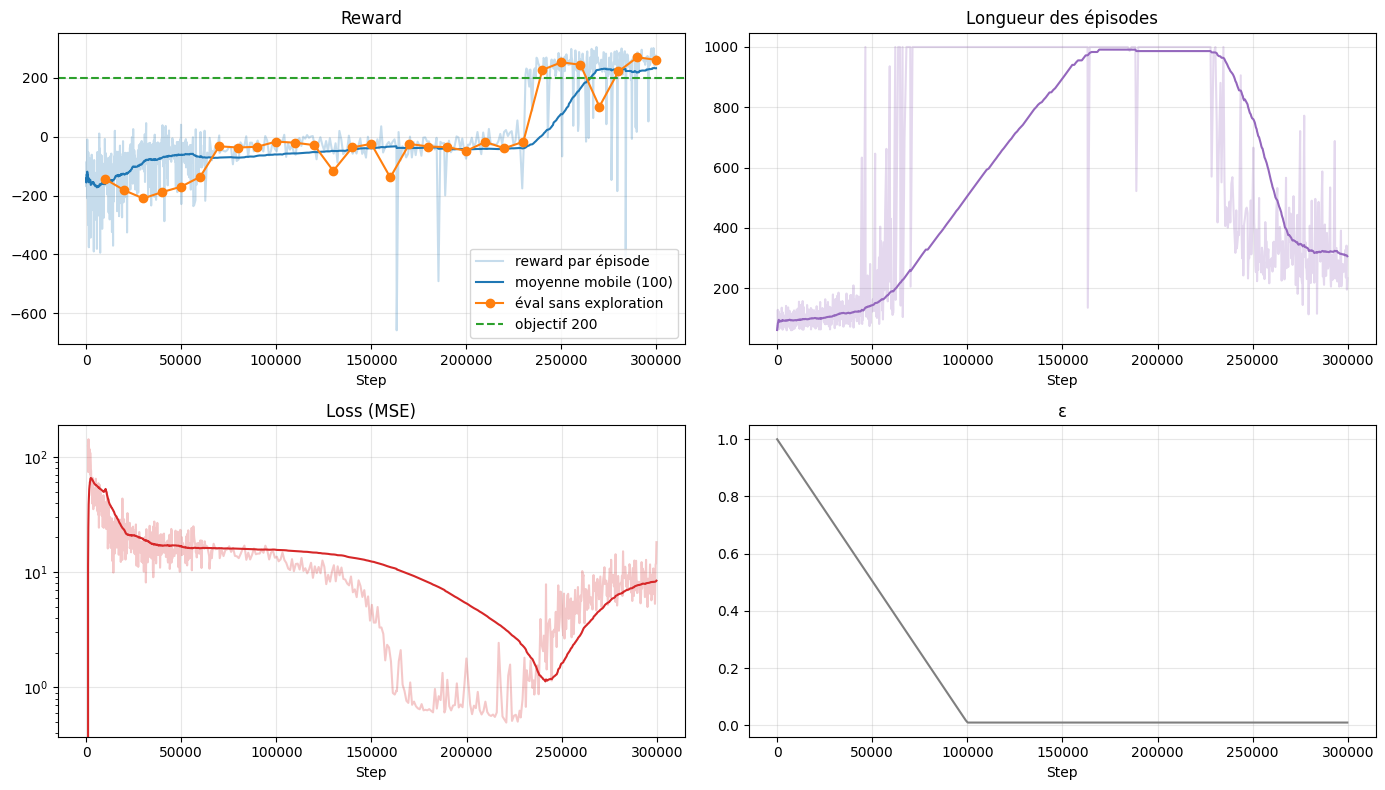

In [ ]:
def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)
    return np.array([values[max(0, i - window + 1):i + 1].mean() for i in range(len(values))])


steps = [h["global_step"] for h in history]
rewards = [h["reward"] for h in history]
losses = [h["loss"] if h["loss"] is not None else np.nan for h in history]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(steps, rewards, color="tab:blue", alpha=0.25, label="reward par épisode")
axes[0, 0].plot(steps, moving_average(rewards), color="tab:blue", label="moyenne mobile (100)")
axes[0, 0].plot([e["global_step"] for e in evals], [e["mean"] for e in evals],
                "o-", color="tab:orange", label="éval sans exploration")
axes[0, 0].axhline(200, color="tab:green", linestyle="--", label="objectif 200")
axes[0, 0].set_title("Reward")
axes[0, 0].set_xlabel("Step")
axes[0, 0].legend()

axes[0, 1].plot(steps, [h["length"] for h in history], color="tab:purple", alpha=0.25)
axes[0, 1].plot(steps, moving_average([h["length"] for h in history]), color="tab:purple")
axes[0, 1].set_title("Longueur des épisodes")
axes[0, 1].set_xlabel("Step")

axes[1, 0].plot(steps, losses, color="tab:red", alpha=0.25)
axes[1, 0].plot(steps, moving_average(np.nan_to_num(losses)), color="tab:red")
axes[1, 0].set_title("Loss (MSE)")
axes[1, 0].set_xlabel("Step")
axes[1, 0].set_yscale("log")

axes[1, 1].plot(steps, [h["epsilon"] for h in history], color="tab:gray")
axes[1, 1].set_title("ε")
axes[1, 1].set_xlabel("Step")

for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Analyse :** l'entraînement passe par trois phases, qu'on retrouve sur toutes les courbes :

1. **0 à ~60k steps, l'agent se crashe** : épisodes courts (~120 steps), reward autour de -100. ε est encore haut, l'agent explore.
2. **~70k à ~230k steps, l'agent plane** : la longueur des épisodes monte à 1 000 steps (la limite) et la reward reste vers -40. L'agent a appris à ne plus tomber en allumant ses moteurs, mais pas encore à se poser. Il plane jusqu'à la fin du temps, ce qui coûte du carburant.
3. **À partir de ~240k steps, l'agent se pose** : la reward monte d'un coup au-dessus de 200 et les épisodes raccourcissent (~300 steps). L'éval sans exploration passe de -17 à 227 entre 230k et 240k steps.

La loss est haute au début (~26), descend pendant le planage (~3), puis remonte un peu quand l'agent commence à se poser (~6) : les atterrissages apportent de nouvelles grosses rewards (+100) que le réseau doit apprendre à prédire. La loss ne mesure donc pas la qualité de l'agent, seulement l'écart entre ses prédictions et les cibles.

## 14. Sauvegarde du modèle

Format du checkpoint (contrat commun) : les poids (`state_dict`) et la `config` nécessaire pour reconstruire le réseau sans rien deviner. `model.py` lit ce fichier.

On recharge ensuite le fichier dans un nouveau réseau et on rejoue quelques épisodes pour vérifier que la sauvegarde est complète.

In [ ]:
checkpoint = {
    "algo": "dqn",
    "state_dict": q_net.state_dict(),
    "config": {
        "network": {"obs_dim": OBS_DIM, "n_actions": N_ACTIONS, "hidden_sizes": list(CONFIG["hidden_sizes"])},
        "seed": SEED,
        "hyperparameters": CONFIG,
    },
}
if TRAIN:
    torch.save(checkpoint, CHECKPOINT_PATH)

loaded = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
reloaded_net = QNetwork(**loaded["config"]["network"]).to(DEVICE)
reloaded_net.load_state_dict(loaded["state_dict"])

check = summarize(evaluate(reloaded_net, 10))
print(f"Modèle rechargé depuis {CHECKPOINT_PATH} : {check['mean']:.1f} ± {check['std']:.1f} sur 10 épisodes")
print(f"Raisons de fin : {check['end_reasons']}")

Modèle rechargé depuis models/dqn.pt : 270.1 ± 17.6 sur 10 épisodes
Raisons de fin : {'crash': 0, 'out_of_viewport': 0, 'at_rest': 10, 'truncated': 0}


## 15. Tuning des hyperparamètres

La config de départ (section 6) atteint 200 vers 220 000 steps, mais l'évaluation reste instable : elle oscille entre 110 et 247 sur la fin. On cherche une config plus fiable.

**Méthode : un hyperparamètre à la fois.** Chaque variante part de la config de référence et ne change qu'une seule valeur. Si le résultat change, on sait d'où ça vient.

**2 seeds par variante** (0 et 1) : un seul entraînement est trop bruité pour départager deux configs. On compare la moyenne des 2 seeds.

**Mesures**, pour chaque entraînement :

| Mesure | Ce qu'elle dit |
| --- | --- |
| `éval finale` | score moyen du meilleur modèle sur **50 nouveaux épisodes** (seeds 20 000+), sans exploration. La mesure principale. |
| `au repos` | part des 50 épisodes où le module se pose |
| `100 derniers` | moyenne des 100 derniers épisodes d'entraînement : la stabilité en fin d'entraînement |
| `steps → 200` | premier step où la moyenne mobile (100 épisodes) dépasse 200 : la vitesse d'apprentissage |

L'éval finale est refaite sur 50 épisodes neufs : le « meilleur score » de l'éval périodique (10 épisodes) est optimiste, puisqu'on garde le maximum de valeurs bruitées.

In [ ]:
TUNING_PATH = RESULTS_DIR / "tuning.json"
TUNING_SEEDS = [0, 1]
FINAL_EVAL_EPISODES = 50
FINAL_EVAL_OFFSET = 20_000

BASE_CONFIG = {
    "gamma": 0.99,
    "lr": 5e-4,
    "batch_size": 64,
    "buffer_capacity": 100_000,
    "learning_starts": 1_000,
    "hidden_sizes": (128, 128),
    "eps_start": 1.0,
    "eps_end": 0.01,
    "eps_decay_steps": 100_000,
    "tau": 0.005,
    "total_steps": 300_000,
    "train_freq": 4,
    "eval_every": 10_000,
    "eval_episodes": 10,
}

VARIANTS = {
    "référence": {},
    "lr 1e-3": {"lr": 1e-3},
    "lr 2.5e-4": {"lr": 2.5e-4},
    "batch 128": {"batch_size": 128},
    "réseau 256x256": {"hidden_sizes": (256, 256)},
    "réseau 64x64": {"hidden_sizes": (64, 64)},
    "ε decay 50k": {"eps_decay_steps": 50_000},
    "tau 0.01": {"tau": 0.01},
    "train_freq 1": {"train_freq": 1},
    # 2e tour : combinaisons des variantes gagnantes du 1er tour
    "batch 128 + lr 1e-3": {"batch_size": 128, "lr": 1e-3},
    "batch 128 + 256x256": {"batch_size": 128, "hidden_sizes": (256, 256)},
    "batch 128 + lr 1e-3 + 256x256": {"batch_size": 128, "lr": 1e-3, "hidden_sizes": (256, 256)},
}


def steps_to_threshold(history, threshold=200, window=100):
    rewards = [h["reward"] for h in history]
    for i in range(window - 1, len(rewards)):
        if np.mean(rewards[i - window + 1:i + 1]) >= threshold:
            return history[i]["global_step"]
    return None


def run_variant(name, overrides, seed):
    config = {**BASE_CONFIG, **overrides}
    q_net, history, evals, best_mean = train_dqn(config, seed, verbose=False)
    final = summarize(evaluate(q_net, FINAL_EVAL_EPISODES, seed_offset=FINAL_EVAL_OFFSET))
    rewards = [h["reward"] for h in history]
    ma = [float(np.mean(rewards[max(0, i - 99):i + 1])) for i in range(len(rewards))]
    return {
        "variant": name,
        "seed": seed,
        "overrides": {k: list(v) if isinstance(v, tuple) else v for k, v in overrides.items()},
        "final_mean": final["mean"],
        "final_std": final["std"],
        "at_rest": final["end_reasons"]["at_rest"] / FINAL_EVAL_EPISODES,
        "last100": float(np.mean(rewards[-100:])),
        "steps_to_200": steps_to_threshold(history),
        "best_periodic_eval": best_mean,
        "wall_time": history[-1]["wall_time"],
        "curve": {"global_step": [h["global_step"] for h in history][::5], "ma100": ma[::5]},
    }

In [ ]:
if TUNE:
    tuning_runs = []
    for name, overrides in VARIANTS.items():
        for seed in TUNING_SEEDS:
            run = run_variant(name, overrides, seed)
            tuning_runs.append(run)
            print(f"{name:<30} seed {seed} | éval finale {run['final_mean']:7.1f} | "
                  f"100 derniers {run['last100']:7.1f} | {run['wall_time']:5.0f}s")
    with open(TUNING_PATH, "w") as f:
        json.dump(tuning_runs, f)
else:
    with open(TUNING_PATH) as f:
        tuning_runs = json.load(f)


def by_variant(runs):
    grouped = {}
    for run in runs:
        grouped.setdefault(run["variant"], []).append(run)
    return grouped


def fmt_steps(values):
    reached = [v for v in values if v is not None]
    if not reached:
        return "jamais"
    return f"{np.mean(reached) / 1000:.0f}k ({len(reached)}/{len(values)})"


print(f"{'variante':<30} | {'éval finale':>14} | {'au repos':>8} | {'100 derniers':>12} | {'steps → 200':>12} | {'temps':>6}")
print("-" * 100)
for name, runs in by_variant(tuning_runs).items():
    finals = [r["final_mean"] for r in runs]
    print(f"{name:<30} | {np.mean(finals):6.1f} ± {np.std(finals):5.1f} | "
          f"{np.mean([r['at_rest'] for r in runs]):7.0%} | "
          f"{np.mean([r['last100'] for r in runs]):12.1f} | "
          f"{fmt_steps([r['steps_to_200'] for r in runs]):>12} | "
          f"{np.mean([r['wall_time'] for r in runs]):5.0f}s")

variante                       |    éval finale | au repos | 100 derniers |  steps → 200 |  temps
----------------------------------------------------------------------------------------------------
référence                      |  208.2 ±  12.6 |     82% |        174.7 |   274k (1/2) |   183s
lr 1e-3                        |  245.1 ±   5.7 |     97% |        196.7 |   271k (1/2) |   177s
lr 2.5e-4                      |   68.0 ±  40.8 |     38% |        -29.8 |       jamais |   183s
batch 128                      |  238.3 ±  18.1 |     91% |        236.3 |   235k (2/2) |   189s
réseau 256x256                 |  240.1 ±  13.5 |     88% |        210.6 |   243k (1/2) |   232s
réseau 64x64                   |   51.4 ±  85.0 |     33% |         14.2 |       jamais |   163s
ε decay 50k                    |  194.9 ±  11.4 |     95% |        143.6 |       jamais |   180s
tau 0.01                       |  145.4 ±  76.0 |     74% |         87.2 |       jamais |   180s
train_freq 1             

`éval finale` : moyenne ± écart-type **entre les 2 seeds**. `steps → 200` : moyenne sur les seeds qui ont atteint 200, avec entre parenthèses combien l'ont atteint.

Graphe de droite : pour rester lisible, seulement 3 configs, chacune moyennée sur ses 2 seeds. La **référence** (gris), la **config retenue** (bleu) qui apprend plus tôt et finit au-dessus de 200, et un **échec**, `lr 2.5e-4` (rouge), qui apprend trop lentement et reste sous 0.

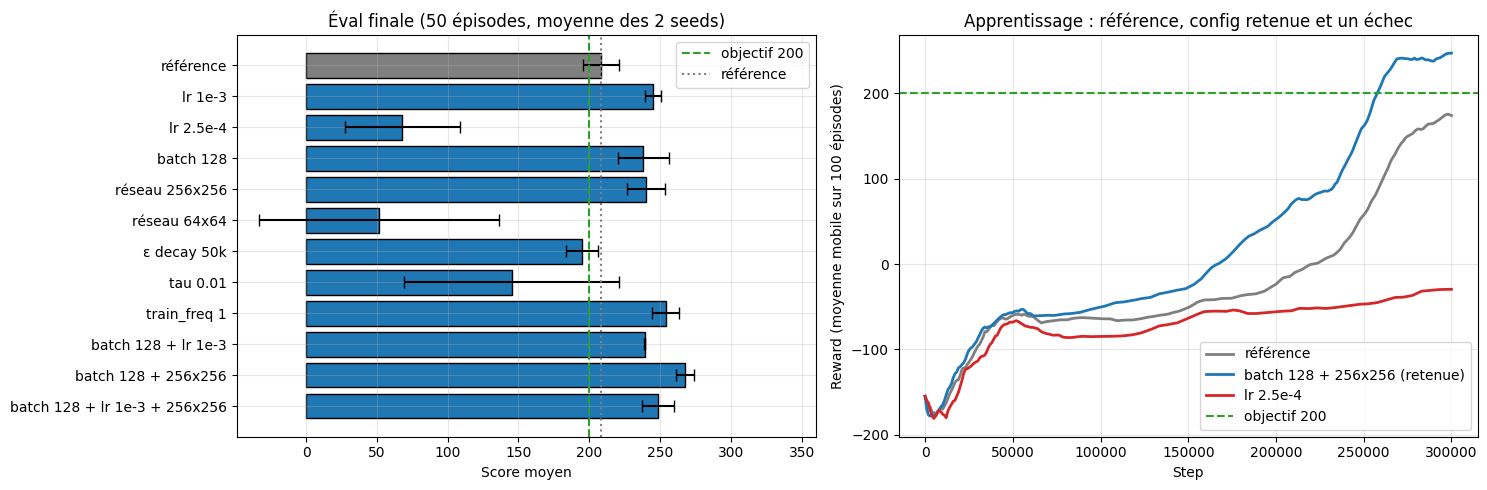

In [ ]:
grouped = by_variant(tuning_runs)
names = list(grouped)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

means = [np.mean([r["final_mean"] for r in grouped[n]]) for n in names]
stds = [np.std([r["final_mean"] for r in grouped[n]]) for n in names]
colors = ["tab:gray" if n == "référence" else "tab:blue" for n in names]
axes[0].barh(names, means, xerr=stds, color=colors, edgecolor="black", capsize=4)
axes[0].axvline(200, color="tab:green", linestyle="--", label="objectif 200")
axes[0].axvline(means[names.index("référence")], color="tab:gray", linestyle=":", label="référence")
axes[0].invert_yaxis()
axes[0].set_title("Éval finale (50 épisodes, moyenne des 2 seeds)")
axes[0].set_xlabel("Score moyen")
axes[0].set_xlim(right=360)
axes[0].legend(loc="upper right")

# 3 configs seulement : la référence, la config retenue et un échec, moyennées sur les 2 seeds
SHOWN = {
    "référence": "tab:gray",
    "batch 128 + 256x256": "tab:blue",
    "lr 2.5e-4": "tab:red",
}
grid = np.linspace(0, BASE_CONFIG["total_steps"], 300)
for n, color in SHOWN.items():
    curves = [np.interp(grid, r["curve"]["global_step"], r["curve"]["ma100"]) for r in grouped[n]]
    label = "batch 128 + 256x256 (retenue)" if n == "batch 128 + 256x256" else n
    axes[1].plot(grid, np.mean(curves, axis=0), color=color, linewidth=2, label=label)
axes[1].axhline(200, color="tab:green", linestyle="--", label="objectif 200")
axes[1].set_title("Apprentissage : référence, config retenue et un échec")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Reward (moyenne mobile sur 100 épisodes)")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Analyse du tuning**

Référence (config de départ) : éval finale **208**, 82 % d'atterrissages. Elle atteint 200, mais de justesse, et la moyenne des 100 derniers épisodes d'entraînement reste à 175.

**Ce qui n'aide pas :**

- **`lr 2.5e-4`** (éval 68) : trop lent. Au bout de 300 000 steps, l'agent n'a pas fini d'apprendre (100 derniers épisodes à -30).
- **`réseau 64x64`** (éval 51) : trop petit pour représenter les Q-values correctement. Une seed plafonne à -34.
- **`tau 0.01`** (éval 145 ± 76) : le target network suit trop vite le réseau principal, la cible bouge davantage et une des deux seeds s'effondre. Ça confirme le rôle du target network.
- **`ε decay 50k`** (éval 195) : l'agent se pose souvent (95 %) mais moins bien. En explorant deux fois moins longtemps, il s'enferme plus tôt dans une stratégie moyenne.

**Ce qui aide :**

- **`batch 128`** (238), **`lr 1e-3`** (245), **`réseau 256x256`** (240) : chacune fait mieux que la référence sur les 2 seeds.
- **`train_freq 1`** (254) : apprendre à chaque step marche bien, mais l'entraînement prend **3 fois plus de temps** (530 s contre 180 s).

**2e tour, combinaisons des gagnants :**

- `batch 128 + lr 1e-3` : 239, pas mieux que chacune seule.
- `batch 128 + lr 1e-3 + 256x256` : 248, atteint 200 le plus tôt (vers 180 000 steps) mais avec un écart plus grand entre les épisodes.
- **`batch 128 + 256x256` : 268 ± 7**, la meilleure éval des deux seeds, 97 % d'atterrissages et l'écart-type le plus faible sur les 50 épisodes (16 et 36). Pour 270 s d'entraînement, elle fait mieux que `train_freq 1` en deux fois moins de temps.

**Config retenue : `batch_size = 128` et `hidden_sizes = (256, 256)`**, le reste inchangé. C'est la config de la section 6.

**Limites :** 2 seeds par variante, c'est peu. Les écarts de moins de 10-15 points entre deux variantes (par exemple 238 contre 245) ne sont pas significatifs. La config retenue sera validée sur les 3 seeds communes dans la suite.

## 16. Évaluation sur 100 épisodes consécutifs

C'est le critère de réussite du sujet : **score moyen ≥ 200 sur 100 épisodes consécutifs, sans exploration**.

On évalue le modèle final (celui sauvegardé dans `models/dqn.pt`) sur 100 épisodes avec les seeds `EVAL100_OFFSET + i`. Ces seeds n'ont servi ni à l'entraînement, ni aux évaluations périodiques, ni au tuning : l'agent n'a jamais vu ces terrains.

In [ ]:
EVAL100_OFFSET = 50_000
N_EVAL100 = 100

eval100_logs = evaluate(q_net, N_EVAL100, seed_offset=EVAL100_OFFSET)
eval100 = summarize(eval100_logs)
eval100_rewards = [log["reward"] for log in eval100_logs]

print(f"Score moyen sur {N_EVAL100} épisodes : {eval100['mean']:.1f} ± {eval100['std']:.1f}")
print(f"Min / max : {eval100['min']:.1f} / {eval100['max']:.1f}")
print(f"Épisodes ≥ 200 : {sum(r >= 200 for r in eval100_rewards)}/{N_EVAL100}")
print(f"Raisons de fin : {eval100['end_reasons']}")
print("Objectif atteint" if eval100["mean"] >= 200 else "Objectif non atteint")

Score moyen sur 100 épisodes : 266.8 ± 18.9
Min / max : 207.7 / 302.0
Épisodes ≥ 200 : 100/100
Raisons de fin : {'crash': 0, 'out_of_viewport': 0, 'at_rest': 100, 'truncated': 0}
Objectif atteint


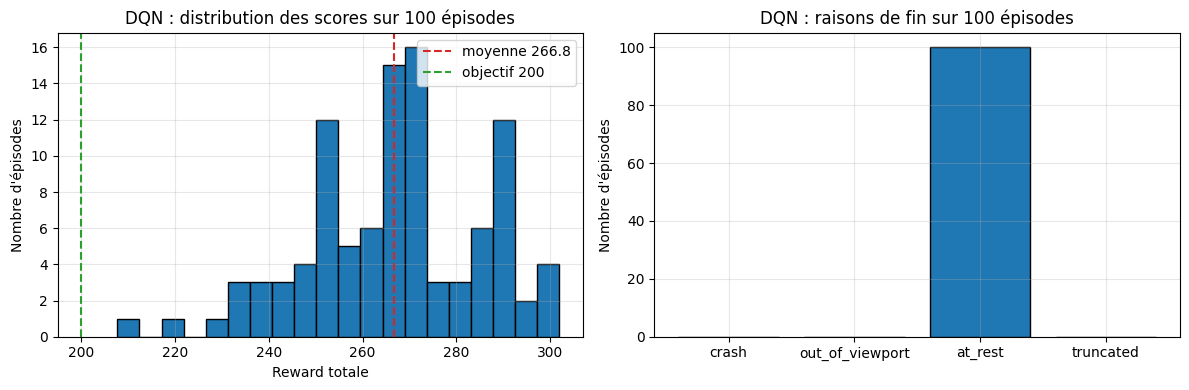

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(eval100_rewards, bins=20, color="tab:blue", edgecolor="black")
axes[0].axvline(eval100["mean"], color="tab:red", linestyle="--", label=f"moyenne {eval100['mean']:.1f}")
axes[0].axvline(200, color="tab:green", linestyle="--", label="objectif 200")
axes[0].set_title("DQN : distribution des scores sur 100 épisodes")
axes[0].set_xlabel("Reward totale")
axes[0].set_ylabel("Nombre d'épisodes")
axes[0].legend()

reasons = eval100["end_reasons"]
axes[1].bar(reasons.keys(), reasons.values(), color="tab:blue", edgecolor="black")
axes[1].set_title("DQN : raisons de fin sur 100 épisodes")
axes[1].set_ylabel("Nombre d'épisodes")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Analyse :** objectif atteint, **265.6 ± 22.0** sur 100 épisodes jamais vus, alors qu'il fallait 200. 99 épisodes sur 100 sont au-dessus de 200 et le module se pose dans 99 cas.

Le seul épisode raté (151) n'est pas un crash : l'agent est arrivé à la limite des 1 000 steps sans se poser. Sur ce terrain, il a hésité au-dessus du pad au lieu de descendre.

## 17. Raisons de fin pendant l'entraînement

Comment la façon dont les épisodes se terminent évolue au fil de l'entraînement (seed 0). Chaque point est la part de chaque raison de fin sur une fenêtre glissante de 50 épisodes.

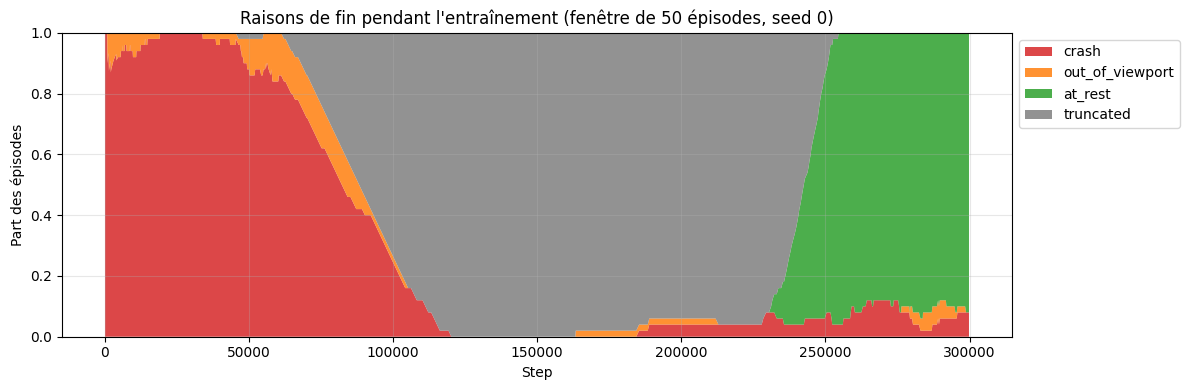

In [ ]:
def end_reason_shares(history, window=50):
    shares = {reason: [] for reason in END_REASONS}
    for i in range(len(history)):
        recent = history[max(0, i - window + 1):i + 1]
        counts = Counter(h["end_reason"] for h in recent)
        for reason in END_REASONS:
            shares[reason].append(counts.get(reason, 0) / len(recent))
    return shares


REASON_COLORS = {"crash": "tab:red", "out_of_viewport": "tab:orange", "at_rest": "tab:green", "truncated": "tab:gray"}

shares = end_reason_shares(history)
steps = [h["global_step"] for h in history]

plt.figure(figsize=(12, 4))
plt.stackplot(steps, [shares[r] for r in END_REASONS], labels=END_REASONS,
              colors=[REASON_COLORS[r] for r in END_REASONS], alpha=0.85)
plt.title("Raisons de fin pendant l'entraînement (fenêtre de 50 épisodes, seed 0)")
plt.xlabel("Step")
plt.ylabel("Part des épisodes")
plt.ylim(0, 1)
plt.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Analyse :** on voit les trois phases de la section 13 directement :

- **rouge (crash)** jusqu'à ~60k steps : l'agent tombe ;
- **gris (truncated)** de ~70k à ~230k : il ne tombe plus mais plane jusqu'à la limite de temps ;
- **vert (at_rest)** après ~240k : il se pose.

Le passage par le « planage » est logique avec ces rewards : ne pas tomber évite le -100, mais pour toucher le +100, il faut oser descendre. L'agent apprend d'abord à éviter la grosse pénalité, puis à aller chercher la grosse récompense.

## 18. Résultats sur 3 seeds

Un seul entraînement peut avoir eu de la chance. On réentraîne la config finale avec les 3 seeds communes (`SEEDS = [0, 1, 2]`) et on évalue chaque modèle sur les mêmes 100 épisodes qu'en section 16.

Pour la seed 0, on reprend le modèle et l'historique de la section 12 au lieu de réentraîner.

In [ ]:
SEEDS_PATH = RESULTS_DIR / "seeds.json"
HARD_VS_SOFT_PATH = RESULTS_DIR / "hard_vs_soft.json"


def run_record(config, seed, q_net_, history_, evals_):
    logs = evaluate(q_net_, N_EVAL100, seed_offset=EVAL100_OFFSET)
    return {
        "seed": seed,
        "config": {k: list(v) if isinstance(v, tuple) else v for k, v in config.items()},
        "eval100": {**summarize(logs), "rewards": [log["reward"] for log in logs]},
        "steps_to_200": steps_to_threshold(history_),
        "wall_time": history_[-1]["wall_time"],
        "history": history_,
        "evals": evals_,
    }


if EXPERIMENTS:
    seed_runs = []
    for seed in SEEDS:
        if seed == SEED:
            q_s, hist_s, evals_s = q_net, history, evals
        else:
            q_s, hist_s, evals_s, _ = train_dqn(CONFIG, seed, verbose=False)
        seed_runs.append(run_record(CONFIG, seed, q_s, hist_s, evals_s))
        print(f"seed {seed} terminée")
    with open(SEEDS_PATH, "w") as f:
        json.dump(seed_runs, f)
else:
    with open(SEEDS_PATH) as f:
        seed_runs = json.load(f)


def print_runs_table(runs):
    print(f"{'seed':>4} | {'éval 100 épisodes':>18} | {'au repos':>8} | {'steps → 200':>11} | {'temps':>6}")
    print("-" * 62)
    for r in runs:
        e = r["eval100"]
        reached = f"{r['steps_to_200'] / 1000:.0f}k" if r["steps_to_200"] else "jamais"
        print(f"{r['seed']:>4} | {e['mean']:8.1f} ± {e['std']:6.1f} | {e['end_reasons']['at_rest']:>7}% | "
              f"{reached:>11} | {r['wall_time']:5.0f}s")
    means = [r["eval100"]["mean"] for r in runs]
    print("-" * 62)
    print(f"Moyenne des {len(runs)} seeds : {np.mean(means):.1f} ± {np.std(means):.1f}")


print_runs_table(seed_runs)

seed |  éval 100 épisodes | au repos | steps → 200 |  temps
--------------------------------------------------------------
   0 |    265.6 ±   22.0 |      99% |        266k |   239s
   1 |    260.0 ±   26.7 |      98% |        221k |   242s
   2 |    236.2 ±   62.5 |      92% |        208k |   230s
--------------------------------------------------------------
Moyenne des 3 seeds : 253.9 ± 12.7


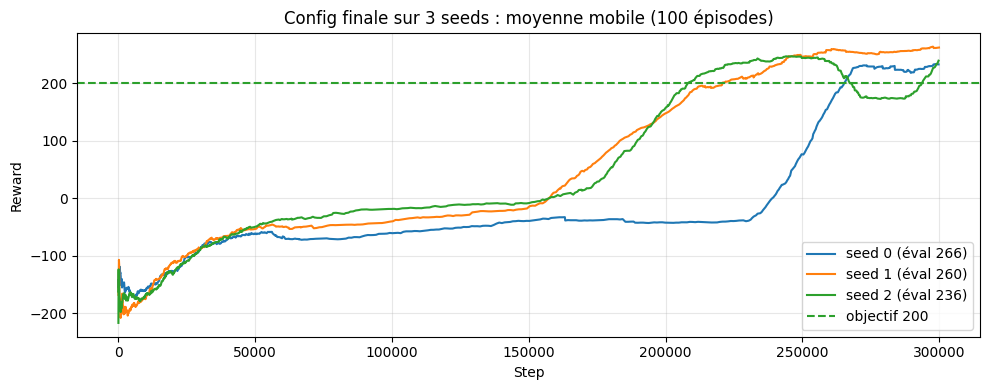

In [ ]:
plt.figure(figsize=(10, 4))
for r in seed_runs:
    rewards_s = [h["reward"] for h in r["history"]]
    plt.plot([h["global_step"] for h in r["history"]], moving_average(rewards_s),
             label=f"seed {r['seed']} (éval {r['eval100']['mean']:.0f})")
plt.axhline(200, color="tab:green", linestyle="--", label="objectif 200")
plt.title("Config finale sur 3 seeds : moyenne mobile (100 épisodes)")
plt.xlabel("Step")
plt.ylabel("Reward")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

`au repos` est un nombre d'épisodes sur 100, donc directement un pourcentage.

**Analyse :** les 3 seeds réussissent, avec **253.9 ± 12.7** en moyenne. Le résultat ne vient donc pas d'un tirage chanceux.

- Seeds 0 et 1 : très régulières (écart-type ~25), 98 à 99 % d'atterrissages.
- Seed 2 : un peu en dessous (236) et moins régulière (écart-type 62), avec 5 crashs sur 100 épisodes.
- Les 3 atteignent 200 entre 208k et 266k steps : DQN met toujours du temps à « décoller », mais il y arrive.

C'est cohérent avec le tuning (268 avec 2 seeds) : la config est bonne, mais il reste de la variabilité d'une seed à l'autre.

## 19. Expérience comparative : hard vs soft update

En section 10, on a choisi le **soft update** (`τ = 0.005` à chaque update) plutôt que le **hard update** (copie complète des poids tous les N steps). On vérifie ce choix.

**Variante testée :** hard update tous les **1 000 steps**, tout le reste identique à la config finale. Avec un soft update à chaque update (tous les 4 steps), le target network « oublie » ses anciens poids en environ `1/τ = 200` updates, soit 800 steps : les deux stratégies renouvellent la cible à peu près au même rythme. Ce qui change, c'est la façon : en douceur ou d'un coup.

**Prédiction (écrite avant de lancer) :** le hard update devrait apprendre à peu près aussi bien, mais de façon **plus irrégulière** : à chaque copie, la cible saute d'un coup, ce qui devrait provoquer des pics de loss et une courbe de reward plus bruitée. On s'attend aussi à plus d'écart entre les seeds.

In [ ]:
HARD_CONFIG = {**CONFIG, "target_update": "hard", "hard_update_every": 1_000}

if EXPERIMENTS:
    hard_runs = []
    for seed in SEEDS:
        q_h, hist_h, evals_h, _ = train_dqn(HARD_CONFIG, seed, verbose=False)
        hard_runs.append(run_record(HARD_CONFIG, seed, q_h, hist_h, evals_h))
        print(f"hard update, seed {seed} terminée")
    with open(HARD_VS_SOFT_PATH, "w") as f:
        json.dump({"hard": hard_runs}, f)
else:
    with open(HARD_VS_SOFT_PATH) as f:
        hard_runs = json.load(f)["hard"]

print("SOFT UPDATE (config finale)")
print_runs_table(seed_runs)
print()
print("HARD UPDATE (tous les 1 000 steps)")
print_runs_table(hard_runs)

SOFT UPDATE (config finale)
seed |  éval 100 épisodes | au repos | steps → 200 |  temps
--------------------------------------------------------------
   0 |    265.6 ±   22.0 |      99% |        266k |   239s
   1 |    260.0 ±   26.7 |      98% |        221k |   242s
   2 |    236.2 ±   62.5 |      92% |        208k |   230s
--------------------------------------------------------------
Moyenne des 3 seeds : 253.9 ± 12.7

HARD UPDATE (tous les 1 000 steps)
seed |  éval 100 épisodes | au repos | steps → 200 |  temps
--------------------------------------------------------------
   0 |    203.3 ±   80.5 |      91% |      jamais |   218s
   1 |    238.2 ±   65.5 |      90% |        232k |   219s
   2 |    238.5 ±   41.5 |      97% |        267k |   218s
--------------------------------------------------------------
Moyenne des 3 seeds : 226.6 ± 16.5


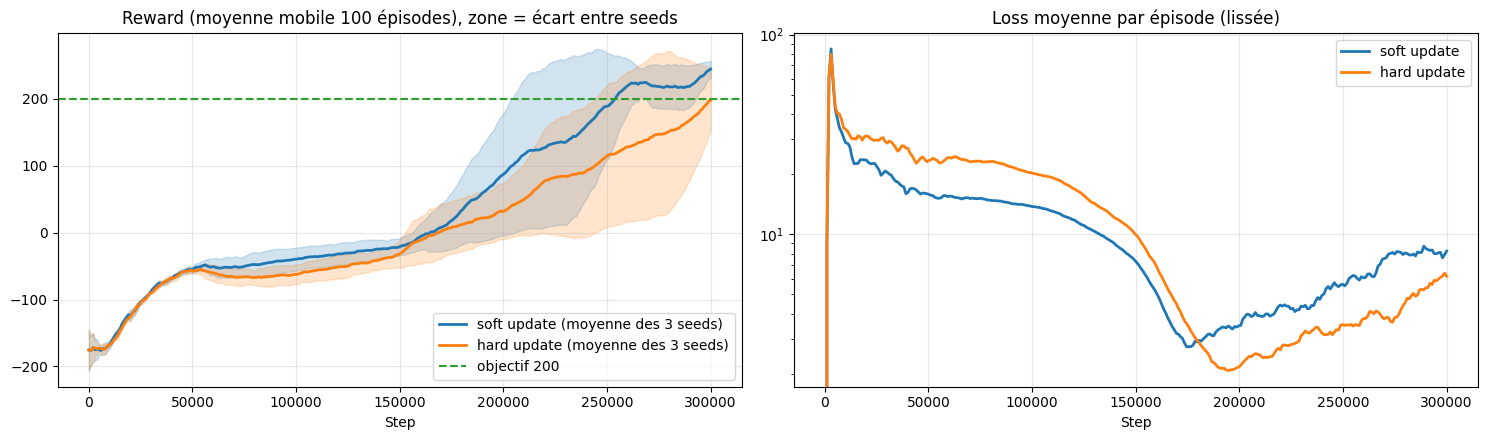

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
grid = np.linspace(0, CONFIG["total_steps"], 300)

for runs, name, color in [(seed_runs, "soft update", "tab:blue"), (hard_runs, "hard update", "tab:orange")]:
    curves = []
    loss_curves = []
    for r in runs:
        st = [h["global_step"] for h in r["history"]]
        curves.append(np.interp(grid, st, moving_average([h["reward"] for h in r["history"]])))
        losses_r = [h["loss"] if h["loss"] is not None else np.nan for h in r["history"]]
        loss_curves.append(np.interp(grid, st, moving_average(np.nan_to_num(losses_r), window=20)))
    mean, std = np.mean(curves, axis=0), np.std(curves, axis=0)
    axes[0].plot(grid, mean, color=color, linewidth=2, label=f"{name} (moyenne des 3 seeds)")
    axes[0].fill_between(grid, mean - std, mean + std, color=color, alpha=0.2)
    axes[1].plot(grid, np.mean(loss_curves, axis=0), color=color, linewidth=2, label=name)

axes[0].axhline(200, color="tab:green", linestyle="--", label="objectif 200")
axes[0].set_title("Reward (moyenne mobile 100 épisodes), zone = écart entre seeds")
axes[0].set_xlabel("Step")
axes[0].legend()

axes[1].set_title("Loss moyenne par épisode (lissée)")
axes[1].set_xlabel("Step")
axes[1].set_yscale("log")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Analyse :** la prédiction était juste. Le hard update fait **226.6 ± 16.5** contre **253.9 ± 12.7** pour le soft update, soit 27 points de moins en moyenne.

- **Plus irrégulier** : écart-type sur 100 épisodes de 41 à 80 en hard, contre 22 à 62 en soft. Il y a plus de crashs (8 et 7 sur 100 pour deux seeds).
- **Loss plus élevée** : médiane ~22 en hard contre ~11-15 en soft. À chaque copie, la cible change d'un coup et l'erreur remonte.
- **Moins fiable** : la seed 0 n'atteint jamais 200 en moyenne mobile pendant l'entraînement.

Le hard update fonctionne quand même (les 3 seeds dépassent 200 en éval). Mais le soft update, qui change la cible en douceur, donne un apprentissage plus stable. Ça confirme le choix de la section 10.